**This project predicts medical insurance costs using machine learning
and audits the model for demographic bias.
The goal is to ensure that predictions are both accurate and fair
across demographic groups such as gender.**

**Import Liabraries**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

**Load Dataset**
- To See complete Dataset Structure(rows,columns)

In [3]:
df = pd.read_csv('insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


**Data Information and shape and sizes**

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [5]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [6]:
df.shape

(1338, 7)

**Data Preprocessing**  (Check Missing values)

In [7]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

**Exploratory Data Analysis (EDA)**

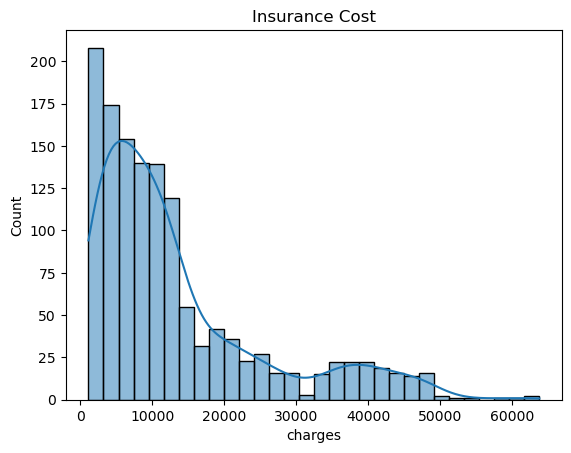

In [8]:
sns.histplot(df['charges'], kde=True) # To check data is skewed or not. if skewed whcih skewed Right skewed or left skewed
plt.title('Insurance Cost')
plt.show()

Smoking Vs Cost

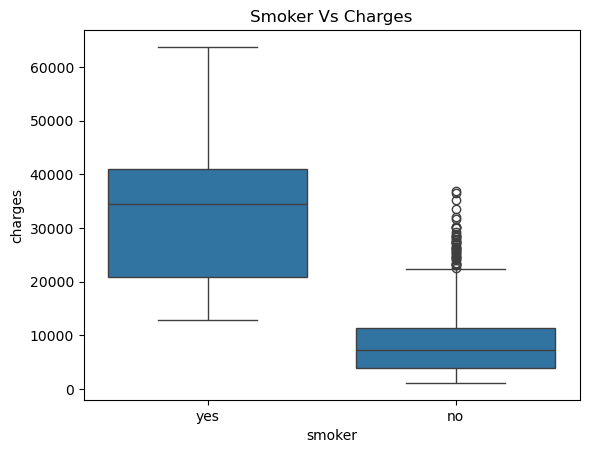

In [9]:
sns.boxplot(x='smoker',y='charges', data=df)
plt.title('Smoker Vs Charges')
plt.show()

In [10]:
df['sex'].value_counts()

sex
male      676
female    662
Name: count, dtype: int64

**Feature Encoding**  (Categories Data to Numerical Data)
- ML Cannot Understand text categorical Data so using func(get_dummies) for multiple columns can change categories to numerical. <br>
Example:
- Male -> (1)
- Female-> (0)
- drop_first=True ?.. To avoid dummy variable trap.

In [11]:
df = pd.get_dummies(df, drop_first=True)
df.head(3)

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.90,0,16884.9240,False,True,False,False,True
1,18,33.77,1,1725.5523,True,False,False,True,False
2,28,33.00,3,4449.4620,True,False,False,True,False


**Train Test Split**
- split data to avoid overfitting or predict data
- We split the data to evaluate the model on unseen data and ensure it generalizes well without overfitting to the training set.

In [12]:
X = df.drop('charges',axis=1)
y = df['charges']

In [13]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

**Train Models**
- handles nonlinear relationships
- strong baseline model

**Random Forest Regressor**
- It builds multiple decision trees independently and averages their results to provide stable, noise-resistant predictions for insurance costs. It’s excellent for capturing complex patterns without needing much fine-tuning.<br>

**XGBoost Regressor**
- It builds trees sequentially, with each new tree specifically correcting the errors of the previous one to achieve maximum accuracy. This "boosting" approach makes it one of the most powerful tools for high-performance tabular data tasks.

In [14]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor()
rf.fit(X_train, y_train)

RandomForestRegressor()

In [15]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


**XGBoost**
- one of the best tabular models
- high accuracy

In [16]:
from xgboost import XGBRegressor
xgb = XGBRegressor()
xgb.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)

**Model Evaluation** <br>
Why R²?
- It measures how well predictions match reality.
- if Score is 1; it is perfect, if 0.8 then it is very Good, else 0.5 it is weak

In [17]:
rf_pred = rf.predict(X_test)
xgb_pred = xgb.predict(X_test)
print('RF R2:\n',y_test,rf_pred)
print('\n XGB R2:\n',y_test,xgb_pred)

RF R2:
 764      9095.06825
887      5272.17580
890     29330.98315
1293     9301.89355
259     33750.29180
           ...     
109     47055.53210
575     12222.89830
535      6067.12675
543     63770.42801
846      9872.70100
Name: charges, Length: 268, dtype: float64 [ 9657.8666487   5110.82782125 28232.6332765  10984.7709773
 34812.6175435   8999.504258    2117.9830955  14707.405837
  5637.7580267  10739.0807527  19730.6370833   8015.901861
  4439.4030749  45587.8517167  48370.9939865  45120.3495365
  9912.4921435  42877.2373921   8651.6759924  24076.0502692
  8864.5448655   9621.6418413   2065.1560479   2335.265019
 12263.0378471  11961.2088561  13587.6963488   6932.686944
 10887.7734128   6798.96052582  7815.9670074  11847.279723
  3770.3403753   5822.2265968   3397.7740865  10215.6852341
  2967.1616797   7899.2773816  23748.7607595  39058.965577
  5664.605274    4095.6261937  12759.7386868  13871.7883955
  6632.661323   15224.9787514  18426.6326292  10212.7564258
 42000.8971749 

**Fairness Analysis**
- we can check bias. Gender Bias
- checking if our model’s predictions are biased or unfair toward specific groups of people based on attributes like age, gender, or smoking status.

In [18]:
X_test['prediction'] = rf_pred
X_test['actual'] = y_test.values

In [19]:
male_avg = X_test[X_test['sex_male'] == 1]['prediction'].mean()
female_avg = X_test[X_test['sex_male'] == 0]['prediction'].mean()

In [20]:
male_avg,female_avg

(np.float64(14438.371178586913), np.float64(12508.836579882976))

In [21]:
pip install aif360

Note: you may need to restart the kernel to use updated packages.


**SHAP**<br>
This shows Feature importance<br>
- smoker(Features) -> highest(impact)
- bmi    -> medium
- age    -> medium


In [22]:
pip install shap

Note: you may need to restart the kernel to use updated packages.


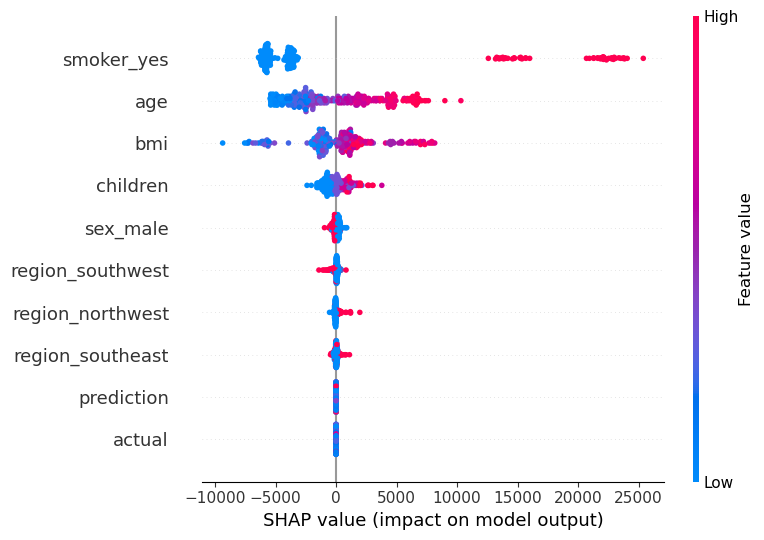

In [23]:
import shap
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values,X_test)

**Save Model**
- we save the model for API usage:

In [24]:
import pickle
pickle.dump(rf, open("../model/model.pkl","wb"))

**FastAPI Prediction API**
- Using FastAPI

In [25]:
pip install fastapi

Note: you may need to restart the kernel to use updated packages.


In [26]:
import pickle
from fastapi import FastAPI

app = FastAPI()

model = pickle.load(open("../model/model.pkl", "rb"))

In [27]:
pip install fastapi uvicorn

Note: you may need to restart the kernel to use updated packages.


In [28]:
pip install python-multipart

Note: you may need to restart the kernel to use updated packages.


In [29]:
pip install mlflow

Note: you may need to restart the kernel to use updated packages.


In [30]:
import mlflow
from sklearn.metrics import r2_score

with mlflow.start_run():
    mlflow.log_metric("R2_score", r2_score(y_test, rf_pred))